In [5]:
!pip -q install yfinance

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
ticker = "TCS.NS"

data = yf.download(
    ticker,
    start="2015-01-01",
    end="2026-01-01",
    auto_adjust=False
)

data.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,,
2015-01-01,965.199463,1272.775024,1283.500000,1270.500000,1283.500000,366830
2015-01-02,978.053284,1289.724976,1295.474976,1275.300049,1275.500000,925740
2015-01-05,963.189880,1270.125000,1299.949951,1262.324951,1290.500000,1754242
2015-01-06,927.680603,1223.300049,1264.550049,1220.000000,1264.550049,2423784
2015-01-07,916.722412,1208.849976,1239.574951,1203.724976,1235.000000,2636332


In [7]:
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data.reset_index()

data.head()

Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2015-01-01,965.199463,1272.775024,1283.500000,1270.500000,1283.500000,366830
1,2015-01-02,978.053284,1289.724976,1295.474976,1275.300049,1275.500000,925740
2,2015-01-05,963.189880,1270.125000,1299.949951,1262.324951,1290.500000,1754242
3,2015-01-06,927.680603,1223.300049,1264.550049,1220.000000,1264.550049,2423784
4,2015-01-07,916.722412,1208.849976,1239.574951,1203.724976,1235.000000,2636332


In [8]:
print("Dataset Shape:", data.shape)

print("\nColumns:")
print(data.columns)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDataset Information:")
data.info()

Dataset Shape: (2716, 7)

Columns:
Index(['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')

Missing Values:
Price
Date         0
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2716 entries, 0 to 2715
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2716 non-null   datetime64[ns]
 1   Adj Close  2716 non-null   float64       
 2   Close      2716 non-null   float64       
 3   High       2716 non-null   float64       
 4   Low        2716 non-null   float64       
 5   Open       2716 non-null   float64       
 6   Volume     2716 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 148.7 KB


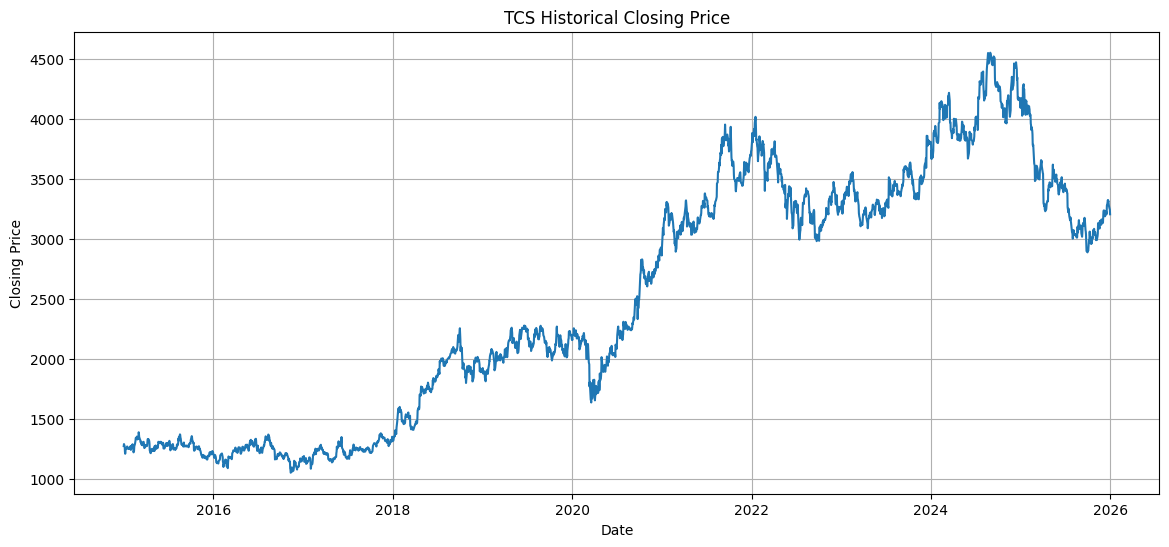

In [9]:
plt.figure(figsize=(14,6))

plt.plot(
    data["Date"],
    data["Close"]
)

plt.title("TCS Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)

plt.show()

In [10]:
data["Previous_Close"] = data["Close"].shift(1)

data["Previous_Open"] = data["Open"].shift(1)

data["Previous_High"] = data["High"].shift(1)

data["Previous_Low"] = data["Low"].shift(1)

data["Previous_Volume"] = data["Volume"].shift(1)

data["MA_5"] = data["Close"].rolling(5).mean()

data["MA_10"] = data["Close"].rolling(10).mean()

data["MA_20"] = data["Close"].rolling(20).mean()

data["Daily_Return"] = (
    data["Close"].pct_change()
)

data["Volatility"] = (
    data["Daily_Return"].rolling(10).std()
)

data["Target"] = data["Close"].shift(-1)

data = data.dropna()

data.head()

Price,Date,Adj Close,Close,High,Low,Open,Volume,Previous_Close,Previous_Open,Previous_High,Previous_Low,Previous_Volume,MA_5,MA_10,MA_20,Daily_Return,Volatility,Target
19,2015-01-29,966.789185,1272.324951,1284.349976,1256.449951,1269.000000,3734392,1269.800049,1251.500000,1272.449951,1251.449951,3121980.0,1260.345020,1259.997510,1255.378754,0.001988,0.006721,1241.025024
20,2015-01-30,943.005310,1241.025024,1287.500000,1235.000000,1280.349976,5817402,1272.324951,1269.000000,1284.349976,1256.449951,3734392.0,1257.195020,1257.145007,1253.791254,-0.024601,0.010135,1257.099976
21,2015-02-02,955.220215,1257.099976,1260.724976,1231.025024,1241.000000,3181802,1241.025024,1280.349976,1287.500000,1235.000000,5817402.0,1258.255005,1256.247510,1252.160004,0.012953,0.011204,1279.125000
22,2015-02-03,971.956177,1279.125000,1282.500000,1253.550049,1255.824951,2345054,1257.099976,1241.000000,1260.724976,1231.025024,3181802.0,1263.875000,1258.610010,1252.610004,0.017521,0.012175,1257.150024
23,2015-02-04,955.258057,1257.150024,1285.849976,1251.050049,1284.000000,2245418,1279.125000,1255.824951,1282.500000,1253.550049,2345054.0,1261.344995,1259.302515,1254.302502,-0.017180,0.013519,1276.199951


In [11]:
features = [
    "Previous_Close",
    "Previous_Open",
    "Previous_High",
    "Previous_Low",
    "Previous_Volume",
    "MA_5",
    "MA_10",
    "MA_20",
    "Daily_Return",
    "Volatility"
]

X = data[features]

y = data["Target"]

print("Features:")
print(X.columns)

print("\nTarget: Next Day Closing Price")

Features:
Index(['Previous_Close', 'Previous_Open', 'Previous_High', 'Previous_Low',
       'Previous_Volume', 'MA_5', 'MA_10', 'MA_20', 'Daily_Return',
       'Volatility'],
      dtype='object', name='Price')

Target: Next Day Closing Price


In [12]:
split = int(len(data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 2156
Testing Samples: 540


In [13]:
linear_model = LinearRegression()

linear_model.fit(
    X_train,
    y_train
)

pred_linear = linear_model.predict(X_test)

In [14]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [15]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        pred_linear
    )
)

pd.DataFrame(results)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,39.778886,55.236028,0.984669


In [16]:
poly_model = Pipeline([
    (
        "polynomial",
        PolynomialFeatures(
            degree=2,
            include_bias=False
        )
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "regression",
        LinearRegression()
    )
])

poly_model.fit(
    X_train,
    y_train
)

pred_poly = poly_model.predict(
    X_test
)

In [17]:
ridge_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge(alpha=1.0)
    )
])

ridge_model.fit(
    X_train,
    y_train
)

pred_ridge = ridge_model.predict(
    X_test
)

In [18]:
lasso_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "lasso",
        Lasso(alpha=0.01)
    )
])

lasso_model.fit(
    X_train,
    y_train
)

pred_lasso = lasso_model.predict(
    X_test
)

In [19]:
svr_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "svr",
        SVR(
            kernel="rbf",
            C=100,
            gamma="scale",
            epsilon=0.1
        )
    )
])

svr_model.fit(
    X_train,
    y_train
)

pred_svr = svr_model.predict(
    X_test
)

In [20]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        pred_linear
    )
)

results.append(
    evaluate_model(
        "Polynomial Regression",
        y_test,
        pred_poly
    )
)

results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        pred_ridge
    )
)

results.append(
    evaluate_model(
        "Lasso Regression",
        y_test,
        pred_lasso
    )
)

results.append(
    evaluate_model(
        "Support Vector Regression",
        y_test,
        pred_svr
    )
)

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,39.778886,55.236028,0.984669
1,Polynomial Regression,35.883179,50.300451,0.987287
2,Ridge Regression,40.531347,56.156826,0.984154
3,Lasso Regression,39.314768,54.749753,0.984938
4,Support Vector Regression,220.217084,358.037058,0.355877


In [21]:
print("Best model based on RMSE:")

best_model = results_df.loc[
    results_df["RMSE"].idxmin()
]

print(best_model)

Best model based on RMSE:
Model       Polynomial Regression
MAE                     35.883179
RMSE                    50.300451
R2 Score                 0.987287
Name: 1, dtype: object


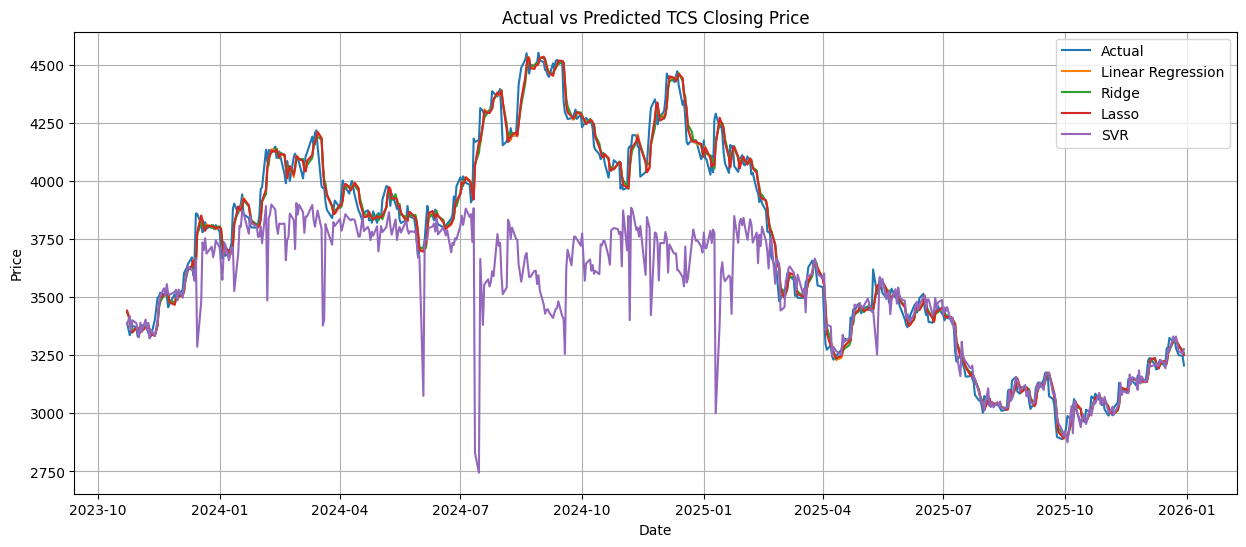

In [22]:
plt.figure(figsize=(15,6))

plt.plot(
    data["Date"].iloc[split:],
    y_test.values,
    label="Actual"
)

plt.plot(
    data["Date"].iloc[split:],
    pred_linear,
    label="Linear Regression"
)

plt.plot(
    data["Date"].iloc[split:],
    pred_ridge,
    label="Ridge"
)

plt.plot(
    data["Date"].iloc[split:],
    pred_lasso,
    label="Lasso"
)

plt.plot(
    data["Date"].iloc[split:],
    pred_svr,
    label="SVR"
)

plt.title(
    "Actual vs Predicted TCS Closing Price"
)

plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()
plt.grid(True)

plt.show()

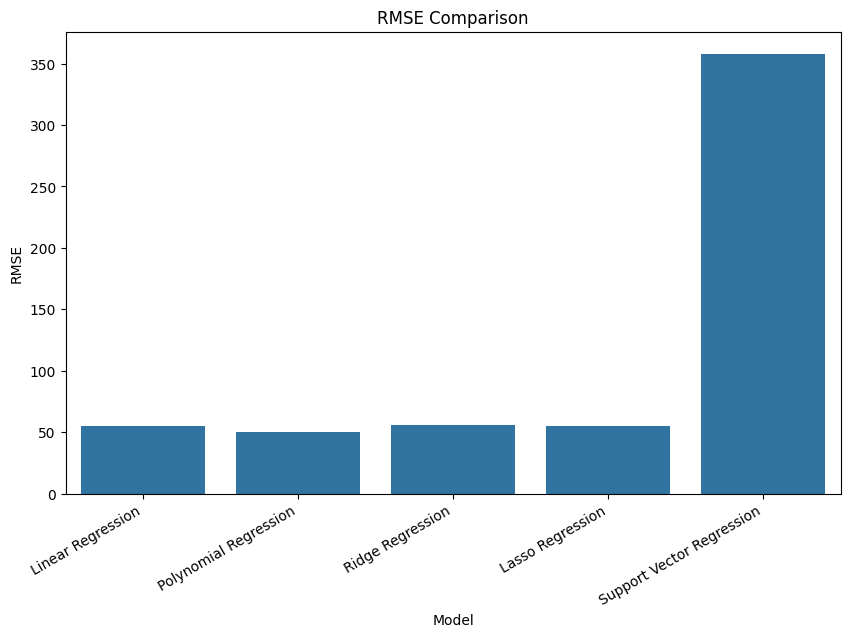

In [23]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.show()

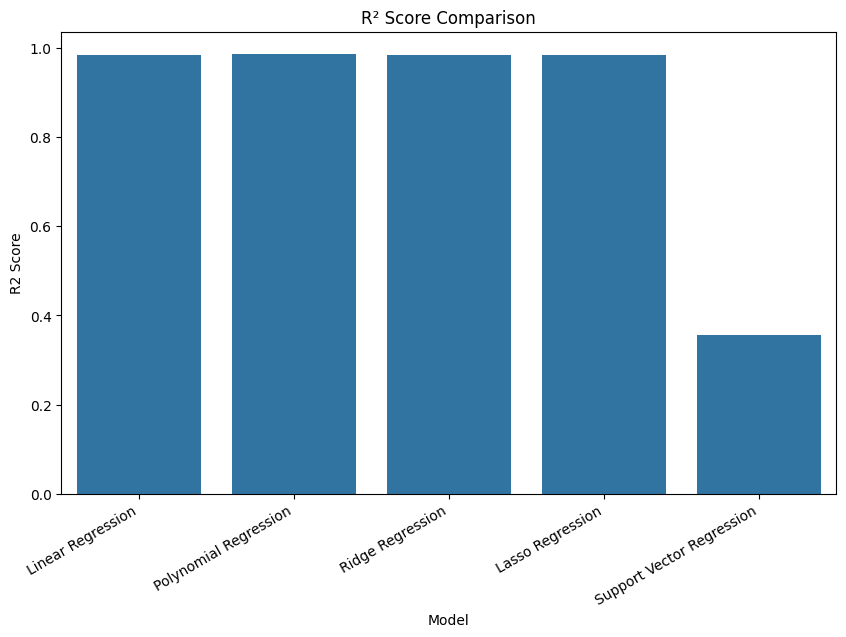

In [24]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("R² Score Comparison")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.show()

In [25]:
tscv = TimeSeriesSplit(
    n_splits=5
)

ridge_cv = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge()
    )
])

cv_scores = []

for train_index, validation_index in tscv.split(X_train):

    X_tr = X_train.iloc[train_index]
    X_val = X_train.iloc[validation_index]

    y_tr = y_train.iloc[train_index]
    y_val = y_train.iloc[validation_index]

    ridge_cv.fit(
        X_tr,
        y_tr
    )

    prediction = ridge_cv.predict(
        X_val
    )

    score = r2_score(
        y_val,
        prediction
    )

    cv_scores.append(score)

print("Cross Validation Scores:")
print(cv_scores)

print(
    "\nMean CV R²:",
    np.mean(cv_scores)
)

Cross Validation Scores:
[0.9416462438242814, 0.9707946918506494, 0.9678596760542185, 0.970233187848731, 0.8925942417404117]

Mean CV R²: 0.9486256082636585


In [26]:
ridge_pipeline = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "ridge",
        Ridge()
    )
])

param_grid = {
    "ridge__alpha": [
        0.001,
        0.01,
        0.1,
        1,
        10,
        100,
        1000
    ]
}

grid_search = GridSearchCV(
    ridge_pipeline,
    param_grid,
    cv=tscv,
    scoring="neg_root_mean_squared_error"
)

grid_search.fit(
    X_train,
    y_train
)

print(
    "Best Parameters:",
    grid_search.best_params_
)

print(
    "Best CV RMSE:",
    -grid_search.best_score_
)

Best Parameters: {'ridge__alpha': 0.001}
Best CV RMSE: 39.674160403439245


In [27]:
best_ridge = grid_search.best_estimator_

pred_tuned_ridge = best_ridge.predict(
    X_test
)

tuned_result = evaluate_model(
    "Tuned Ridge Regression",
    y_test,
    pred_tuned_ridge
)

tuned_result

{'Model': 'Tuned Ridge Regression',
 'MAE': 39.778694765374595,
 'RMSE': np.float64(55.23616637472464),
 'R2 Score': 0.9846693760075825}

In [28]:
latest_features = X.iloc[[-1]]

predicted_next_close = best_ridge.predict(
    latest_features
)[0]

last_close = data["Close"].iloc[-1]

print(
    "Latest Closing Price:",
    round(last_close, 2)
)

print(
    "Predicted Next Trading Day Closing Price:",
    round(predicted_next_close, 2)
)

Latest Closing Price: 3246.8
Predicted Next Trading Day Closing Price: 3253.74


In [29]:
change = (
    predicted_next_close - last_close
)

percentage_change = (
    change / last_close
) * 100

print(
    "Predicted Change:",
    round(change, 2)
)

print(
    "Predicted Percentage Change:",
    round(percentage_change, 2),
    "%"
)

Predicted Change: 6.94
Predicted Percentage Change: 0.21 %
